In [171]:
import requests
import json
import matplotlib.pyplot as plt

In [247]:
# 동영상 ID
video_id = "j_V6PTcCQCc"

get url!!!
get url finished!!!!!


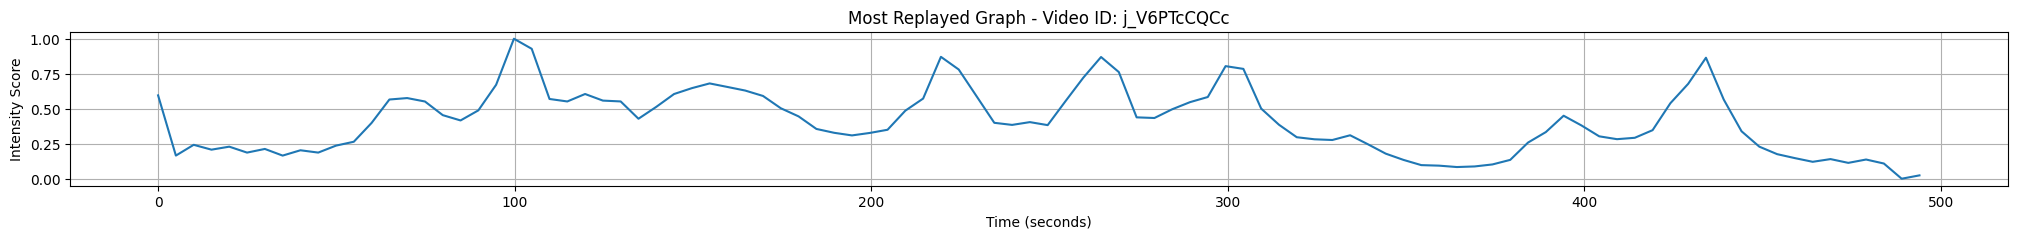

In [248]:
import requests
import json
import matplotlib.pyplot as plt



# API 엔드포인트 URL
url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# API 호출하여 JSON 데이터 가져오기
print('get url!!!')
response = requests.get(url)
print('get url finished!!!!!')
data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


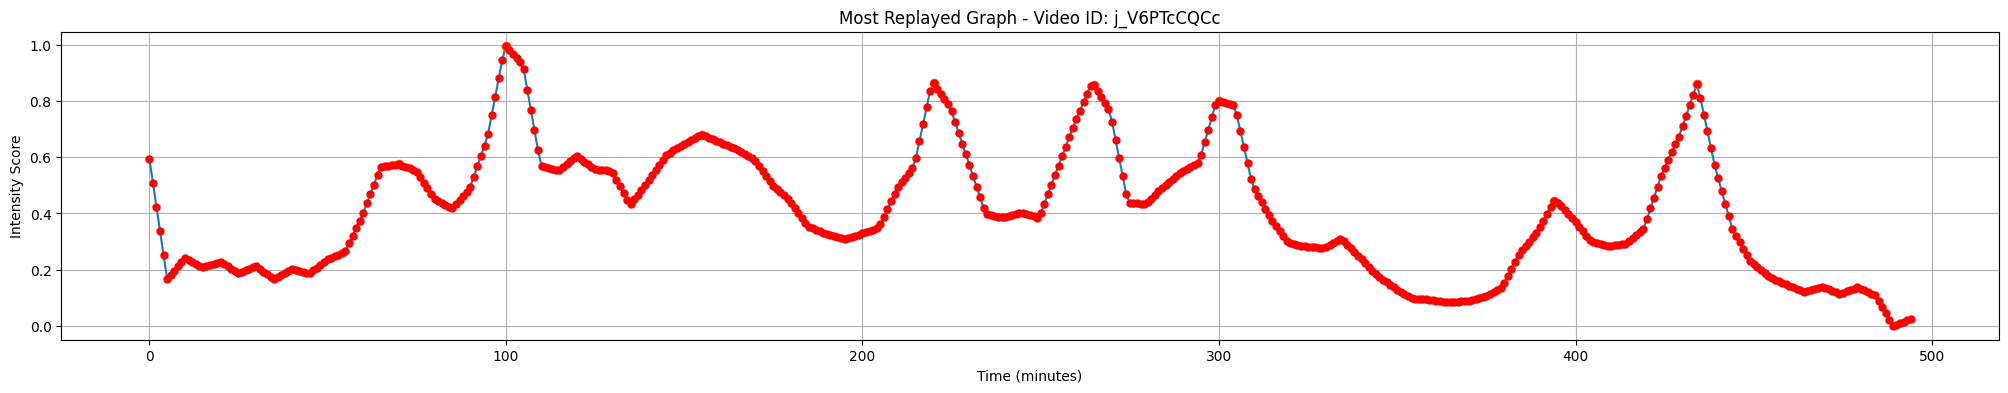

In [249]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(new_time[peaks], smoothed_intensity_scores[peaks], "o", label='Peaks')
plt.scatter(new_time, smoothed_intensity_scores, color='r', label='Selected Points', s=25, zorder=5)

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

In [250]:
class State:
    def __init__(self, time, count, score, gradient):
        self.time = time
        self.count = count
        self.score = score
        self.gradient = gradient
        self.next_states = []  # 접근할 수 있는 인덱스 저장

    def get_info(self):
        info = f'time: {self.time}, Count: {self.count}, Score: {self.score}, Gradient: {self.gradient}, Next State {self.next_states}'
        print(info)


In [251]:
def create_states(smoothed_intensity_scores, max_t):
    gradient = np.gradient(smoothed_intensity_scores)
    abs_gradient = np.abs(gradient)  # 절대값 사용
    normalized_gradient = (abs_gradient - np.min(abs_gradient)) / (np.max(abs_gradient) - np.min(abs_gradient))
    
    states = [[State(time=i, count=j, score=smoothed_intensity_scores[i], gradient=normalized_gradient[i]) 
               for j in range(max_t + 1)] for i in range(len(smoothed_intensity_scores))]
    return states

In [252]:
# 상태들의 next_states를 설정하는 함수
def set_next_states(states, min_time, max_t):
    n = len(states)
    for i in range(n):
        for t in range(max_t + 1):
            if i + 1 < n and t + 1 <= max_t :
                states[i][t].next_states.append((i + 1, t + 1))  # 다음 시간과 새로운 t 값
            if t >= min_time:
                for j in range(i + 2, n):
                    states[i][t].next_states.append((j, 0))  # 다음 상태의 인덱스와 새로운 t 값 0


In [253]:
def DP(states, num_points=30, gradient_weight=0.5):
    n = len(states)
    max_t = num_points
    
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 4), -1, dtype=int)

    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                if dp[i, t, k - 1] != -np.inf:
                    for next_i, next_t in states[i][t].next_states:
                        if next_i < n and next_t <= max_t:
                            # gradient를 고려한 새로운 점수 계산
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score + gradient_weight * states[next_i][next_t].gradient
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t, next_i, next_t)

    return dp, trace

def find_path(states, dp, trace, num_points=30, min_time=4):
    n = len(states)
    max_score = -np.inf
    max_index = (-1, -1, -1)
    for i in range(n):
        for t in range(num_points + 1):
            if t >= min_time:
                if dp[i, t, num_points] > max_score:
                    max_score = dp[i, t, num_points]
                    max_index = (i, t, num_points)

    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        max_index = tuple(trace[max_index[0], max_index[1], k])
        selected_points.append(max_index[0])
        k -= 1
    
    selected_points.reverse()

    return selected_points, max_score

# main

In [266]:
total_time = 60
max_t = total_time
min_time = 10
gradient_weight = 0.1

In [267]:
states = create_states(smoothed_intensity_scores, max_t)

# next_states 설정
set_next_states(states, min_time, max_t)

In [268]:
dp, trace = DP(states, num_points=total_time, gradient_weight= gradient_weight) # 에 가까운 수가 되는거므로...
selected_points, max_score = find_path(states, dp, trace, total_time, min_time)


In [269]:
def group_consecutive_points(points):
    grouped_points = []
    group = [points[0]]
    for i in range(1, len(points)):
        if points[i] == points[i-1] + 1:
            group.append(points[i])
        else:
            grouped_points.append(group)
            group = [points[i]]
    grouped_points.append(group)
    return grouped_points

In [270]:

selected_smoothed_scores = [smoothed_intensity_scores[i] for i in selected_points]

In [271]:
grouped_points = group_consecutive_points(selected_points)
group_sizes = [len(group) for group in grouped_points]

In [272]:
# for group in grouped_points:
#     group.append(group[-1]+1)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


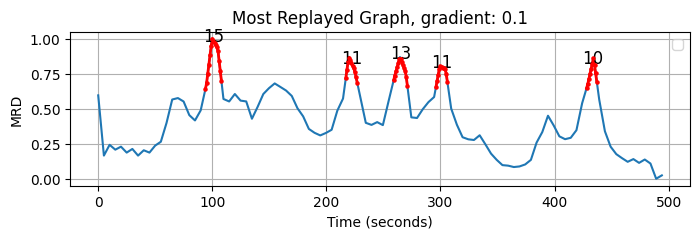

In [273]:
import matplotlib.pyplot as plt
import numpy as np

# 가정: smoothed_intensity_scores와 start_seconds가 이미 정의되어 있음
# intervals = [(1, 7), (32, 38), (86, 114), (141, 146), (157, 162), (202, 208)]
plt.figure(figsize=(8, 2))
plt.plot(start_seconds, intensity_scores)
plt.scatter(selected_points, selected_smoothed_scores, color='r', s=5, zorder=5)

# 연속된 점들의 그룹 크기를 그래프에 표시
for group, size in zip(grouped_points, group_sizes):
    mid_point = group[len(group) // 2]
    plt.text(mid_point, smoothed_intensity_scores[mid_point], str(size), color='black', fontsize=12, ha='center')

for group in grouped_points:
    for i in range(len(group) -1 ):
        plt.plot([group[i], group[i + 1]], [smoothed_intensity_scores[group[i]], smoothed_intensity_scores[group[i + 1]]], color='r', linewidth=2)


plt.title(f'Most Replayed Graph, gradient: {gradient_weight}')
plt.xlabel('Time (seconds)')
plt.ylabel('MRD')
plt.grid(True)
plt.legend()
plt.show()